<a href="https://colab.research.google.com/github/RachmadAprisandhy/PembelajaranMesin/blob/main/JS08/JS08_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()

data = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

data["target"] = iris.target
data["species"] = data["target"].map(
    dict(enumerate(iris.target_names))
)

display(data.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


clustering dengan HDBSCAN

In [2]:
from sklearn.preprocessing import StandardScaler

# Gunakan fitur Iris saja, tanpa target atau nama spesies
X = iris.data

# Standarkan fitur
X_scaled = StandardScaler().fit_transform(X)

In [3]:
try:
    from sklearn.cluster import HDBSCAN
    model = HDBSCAN(min_cluster_size=5, min_samples=3)
except ImportError:
    import hdbscan
    model = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=3)

label_cluster = model.fit_predict(X_scaled)

print("Label cluster untuk 10 data pertama:")
print(label_cluster[:10])

Label cluster untuk 10 data pertama:
[0 0 0 0 0 0 0 0 0 0]


laporkan hasil

In [4]:
import numpy as np

cluster_unik = sorted(set(label_cluster) - {-1})
jumlah_cluster = len(cluster_unik)
jumlah_noise = int(np.sum(label_cluster == -1))

print("Jumlah cluster:", jumlah_cluster)
print("Banyaknya noise:", jumlah_noise)

Jumlah cluster: 2
Banyaknya noise: 0


visualisasi pca

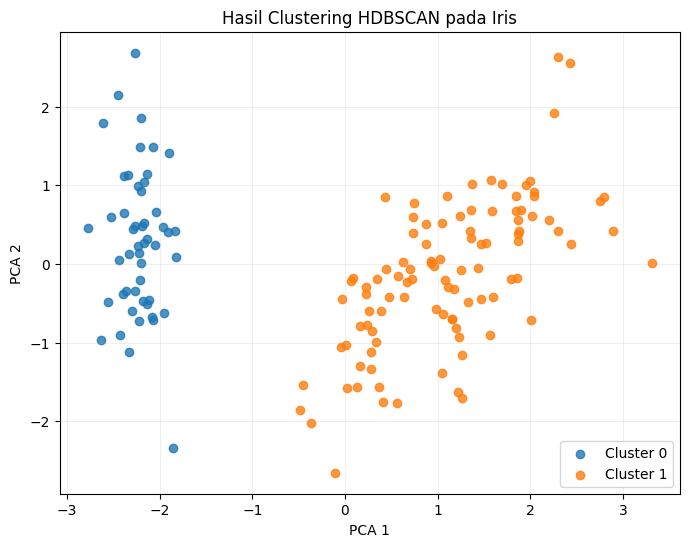

In [5]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X_pca = PCA(n_components=2).fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

for cluster in sorted(set(label_cluster)):
    mask = label_cluster == cluster
    nama = "Noise" if cluster == -1 else f"Cluster {cluster}"

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=nama,
        alpha=0.8,
    )

plt.title("Hasil Clustering HDBSCAN pada Iris")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

In [6]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score

# Bandingkan cluster dengan label spesies asli
print("Adjusted Rand Index:",
      round(adjusted_rand_score(iris.target, label_cluster), 4))

tabel = pd.crosstab(
    pd.Series(label_cluster, name="Cluster HDBSCAN"),
    pd.Series(
        [iris.target_names[i] for i in iris.target],
        name="Spesies asli",
    ),
)
display(tabel)

Adjusted Rand Index: 0.5681


Spesies asli,setosa,versicolor,virginica
Cluster HDBSCAN,,,
0,50,0,0
1,0,50,50


Hasil clustering cukup sesuai dengan label asli, tetapi belum sepenuhnya memisahkan ketiga spesies. HDBSCAN berhasil mengelompokkan seluruh data setosa secara terpisah, tetapi menggabungkan versicolor dan virginica ke cluster yang sama. Nilai ARI 0,5681 menunjukkan kesesuaian sedang dengan label asli.